# Emerging Social Issues & Territorial Needs

## Business Question

What emerging social issues and territorial needs could justify
the development of new services or the adaptation of existing
services at CIDFF Rhône–Arc Alpin?

## Geographic Scope

- Isère (38)
- Rhône (69)
- Savoie (73)
- Haute-Savoie (74)

## Objectives

1. Explore trends in recorded domestic and sexual violence.
2. Compare indicators across the four departments.
3. Examine emerging gender-related issues, including sexism and masculinist attitudes.
4. Identify potential strategic implications for CIDFF.

## Data Limitations

Police-recorded violence does not represent all violence experienced.
National survey results cannot automatically be interpreted as
department-level findings.

## 1. Data Loading & Understanding

This dataset comes from the HCE Sexism Barometer 2025.

Our objective is to explore attitudes related to sexism,
gender stereotypes and antifeminist beliefs.

We first examine the dataset structure before cleaning the data.

In [1]:
import pandas as pd

# Load the HCE Sexism Barometer 2025
df_hce = pd.read_csv(
    "base-de-donnees-toluna-harris-barometre-sexisme-vague-5-2025-dgcs-hce-.csv",
    sep=";"
)

# Check the dataset structure
print("Rows and columns:", df_hce.shape)
print("\nData types:")
print(df_hce.dtypes.value_counts())

Rows and columns: (3061, 264)

Data types:
str        230
float64     22
int64       12
Name: count, dtype: int64


## 2. Data Quality Assessment

Before cleaning the data, we check for duplicate responses
and missing values.

Some missing values may be normal because not all questions
apply to every respondent.

In [2]:
# Are there duplicate responses or missing values?

print("Duplicate response IDs:",
      df_hce["responseid"].duplicated().sum())

# Calculate missing values by column
missing_pct = (
    df_hce.isna().mean() * 100
).sort_values(ascending=False)

print("\nTop 10 columns with missing values (%):")
print(missing_pct.head(10).round(1))

Duplicate response IDs: 0

Top 10 columns with missing values (%):
SEXUALITE_5_other : Autres, précisez (SEXUALITE - De manière générale, vous vous définissez comme ?)                                                                                                        99.4
PCS_REF : PCS_REF - Dans quelle catégorie socioprofessionnelle se situe la personne qui contribue le plus aux revenus de votre foyer ?                                                                      79.4
COUPLE2 : COUPLE2 - Et avez-vous déjà vécu une relation de couple dans le passé ?                                                                                                                           69.0
RECODE_PCS_REF2 : RECODE_PCS_REF2                                                                                                                                                                           68.3
RECODE_PCS_REF : RECODE_PCS_REF                                                                  

In [3]:
# Are the variables selected for our analysis complete?

selected_prefixes = [
    "SEXE :", "REC_AGE3", "POIDS",
    "Q4_19", "Q4_27", "Q4_30",
    "Q4_10", "Q4_29", "Q4_33",
    "Q11_6", "Q11_7"
]

selected_cols = [
    col for col in df_hce.columns
    if any(col.startswith(prefix) for prefix in selected_prefixes)
]

print("Selected columns:", len(selected_cols))

# Check missing values and data types
display(pd.DataFrame({
    "Missing (%)": df_hce[selected_cols].isna().mean().mul(100).round(1),
    "Data type": df_hce[selected_cols].dtypes.astype(str)
}))

Selected columns: 11


,Missing (%),Data type
SEXE : SEXE - Vous êtes :,0.0,str
REC_AGE3 : REC_AGE3,0.0,str
"Q4_10 : Une femme agressée sexuellement peut, en partie, être responsable de sa situation (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)",0.0,str
Q4_19 : Le féminisme menace la place et le rôle des hommes dans la société (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?),0.0,str
"Q4_27 : Lors d’une séparation, les femmes sont avantagées par la justice par rapport aux hommes pour obtenir la garde des enfants (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)",0.0,str
Q4_29 : Il est normal que les femmes acceptent un rapport sexuel pour faire plaisir à leur conjoint (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?),0.0,str
"Q4_30 : A cause du féminisme, il est plus difficile pour les hommes de trouver une compagne et de se mettre en couple (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)",0.0,str
Q4_33 : Quand une femme dit non à un rapport sexuel on peut la convaincre de changer d’avis (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?),0.0,str
"Q11_6 : Être parfois violent pour se faire respecter (Q11 - Pour correspondre à ce qu’on attend des hommes dans la société, pensez-vous qu'il faut… ?)",0.0,str
"Q11_7 : Ne pas montrer ses émotions (Q11 - Pour correspondre à ce qu’on attend des hommes dans la société, pensez-vous qu'il faut… ?)",0.0,str


## 3. Data Cleaning

The selected variables have no missing values in Pandas.

However, some survey answers may include "Don't know" or
"No answer" categories.

We first convert the survey weights into numeric values.

In [4]:
# Create a copy to keep the original data unchanged
df_clean = df_hce.copy()

# Convert survey weights to numeric values
df_clean["POIDS"] = pd.to_numeric(
    df_clean["POIDS"].str.replace(",", ".", regex=False),
    errors="coerce"
)

# Check the conversion
print("Weight data type:", df_clean["POIDS"].dtype)
print("Missing weights:", df_clean["POIDS"].isna().sum())
print("Average weight:", round(df_clean["POIDS"].mean(), 2))

Weight data type: float64
Missing weights: 0
Average weight: 1.0


In [5]:
# Do all selected questions use the same answer categories?

question_cols = [
    col for col in selected_cols
    if col.startswith(("Q4_", "Q11_"))
]

for col in question_cols:
    print("\n", col.split(" : ")[0])
    print(df_clean[col].value_counts(dropna=False))


 Q4_10
Q4_10 : Une femme agressée sexuellement peut, en partie, être responsable de sa situation (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)
Pas du tout d’accord         2016
Plutôt pas d’accord           583
Plutôt d’accord               253
Non réponse / Ne sait pas     124
Tout à fait d’accord           85
Name: count, dtype: int64

 Q4_19
Q4_19 : Le féminisme menace la place et le rôle des hommes dans la société (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)
Pas du tout d’accord         948
Plutôt pas d’accord          858
Plutôt d’accord              646
Tout à fait d’accord         327
Non réponse / Ne sait pas    282
Name: count, dtype: int64

 Q4_27
Q4_27 : Lors d’une séparation, les femmes sont avantagées par la justice par rapport aux hommes pour obtenir la garde des enfants (Q4 - Dans quelle mesure êtes-vous d’accord avec les affirmations suivantes ?)
Plutôt d’accord              1184
Plutôt pas d’accord    

In [6]:
# Can we compare agreement across different survey questions?

# Define positive answers for each question type
positive_answers = [
    "Plutôt d’accord",
    "Tout à fait d’accord",
    "Oui plutôt",
    "Oui tout à fait"
]

negative_answers = [
    "Plutôt pas d’accord",
    "Pas du tout d’accord",
    "Non plutôt pas",
    "Non pas du tout"
]

# Create binary variables without changing original answers
for col in question_cols:
    question_id = col.split(" : ")[0]

    df_clean[question_id + "_binary"] = df_clean[col].map(
        {answer: 1 for answer in positive_answers}
        | {answer: 0 for answer in negative_answers}
    )

# Check the new variables
binary_cols = [col.split(" : ")[0] + "_binary" for col in question_cols]

display(df_clean[binary_cols].count())

Q4_10_binary    2937
Q4_19_binary    2779
Q4_27_binary    2742
Q4_29_binary    2874
Q4_30_binary    2744
Q4_33_binary    2861
Q11_6_binary    2976
Q11_7_binary    2934
dtype: int64

In [7]:
# Are some numeric values stored as text?

text_cols = df_clean.select_dtypes(include=["object", "str"]).columns

for col in text_cols:
    values = df_clean[col].dropna().astype(str).str.strip()

    if len(values) == 0:
        continue

    numeric_values = pd.to_numeric(
        values.str.replace(",", ".", regex=False),
        errors="coerce"
    )

    if numeric_values.notna().mean() > 0.95:
        print(col)

## 4. Exploratory Data Analysis

### 4.1 Overall attitudes

Which sexist or antifeminist attitudes receive the highest levels
of agreement among respondents who expressed an opinion?

We use weighted percentages to compare the eight selected questions.

In [8]:
# Which attitudes have the highest weighted agreement?

results = []

for col in binary_cols:
    valid = df_clean[df_clean[col].notna()]

    # Calculate the weighted percentage
    percentage = (
        (valid[col] * valid["POIDS"]).sum()
        / valid["POIDS"].sum()
        * 100
    )

    results.append({
        "Question": col.replace("_binary", ""),
        "Valid responses": len(valid),
        "Weighted agreement (%)": round(percentage, 1)
    })

# Rank the questions by weighted agreement
df_results = pd.DataFrame(results).sort_values(
    "Weighted agreement (%)",
    ascending=False
)

display(df_results)

,Question,Valid responses,Weighted agreement (%)
2,Q4_27,2742,62.9
4,Q4_30,2744,41.5
1,Q4_19,2779,35.2
7,Q11_7,2934,31.2
3,Q4_29,2874,18.7
5,Q4_33,2861,13.7
6,Q11_6,2976,13.1
0,Q4_10,2937,11.6


### Observation

Q4_27 has the highest weighted agreement (62.9%), followed by
Q4_30 (41.5%) and Q4_19 (35.2%).

These three statements suggest that some respondents perceive
gender equality or feminism as a disadvantage for men.

This raises a question: do these attitudes differ by gender and age?

The results describe national survey responses and cannot be
used to estimate attitudes in the four CIDFF departments.

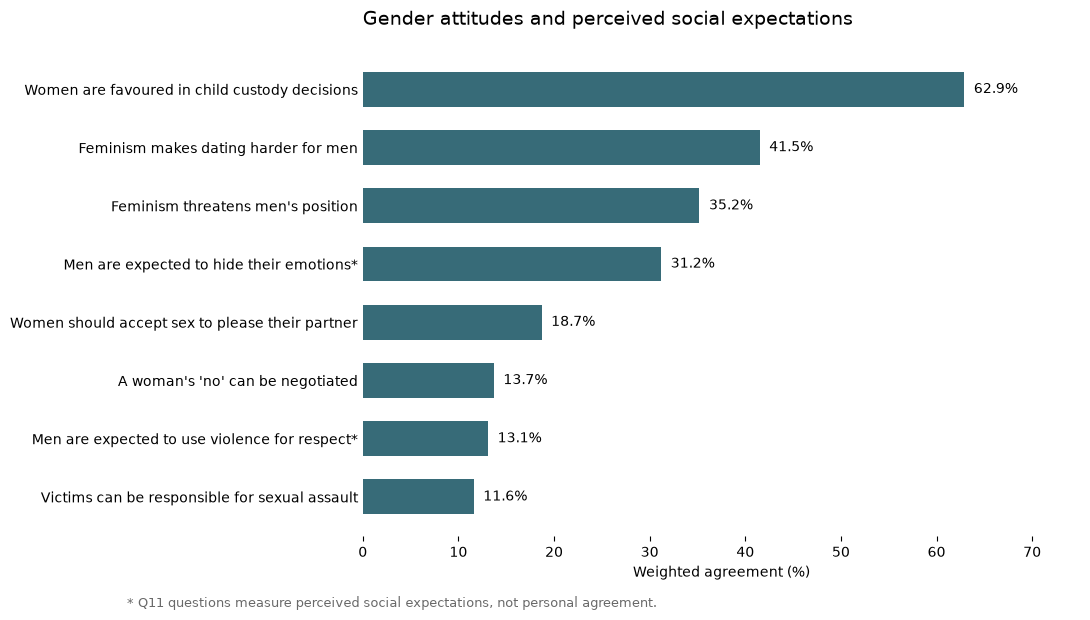

In [9]:
import matplotlib.pyplot as plt

# Short labels for the selected survey questions
question_labels = {
    "Q4_27": "Women are favoured in child custody decisions",
    "Q4_30": "Feminism makes dating harder for men",
    "Q4_19": "Feminism threatens men's position",
    "Q11_7": "Men are expected to hide their emotions*",
    "Q4_29": "Women should accept sex to please their partner",
    "Q4_33": "A woman's 'no' can be negotiated",
    "Q11_6": "Men are expected to use violence for respect*",
    "Q4_10": "Victims can be responsible for sexual assault"
}

plot_data = df_results.copy()
plot_data["Statement"] = plot_data["Question"].map(question_labels)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_data["Statement"],
    plot_data["Weighted agreement (%)"],
    height=0.6,
    color="#376B78"
)

# Display percentages at the end of each bar
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

ax.invert_yaxis()
ax.set_xlim(0, 75)
ax.set_xlabel("Weighted agreement (%)")
ax.set_title(
    "Gender attitudes and perceived social expectations",
    loc="left",
    fontsize=14,
    pad=18
)

# Remove unnecessary borders and grid
for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0)
ax.grid(False)

fig.text(
    0.12, -0.02,
    "* Q11 questions measure perceived social expectations, not personal agreement.",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout()
plt.show()

### 4.2 Gender differences

Do men and women express the same levels of agreement
with sexist and antifeminist statements?

We compare weighted percentages by gender to identify
possible differences in attitudes.

In [10]:
# Check the gender categories in the dataset

gender_col = [
    col for col in df_clean.columns
    if col.startswith("SEXE :")
][0]

print("Column:", gender_col)
print("\nGender categories:")
print(df_clean[gender_col].value_counts(dropna=False))

Column: SEXE : SEXE - Vous êtes :

Gender categories:
SEXE : SEXE - Vous êtes :
Une femme    1610
Un homme     1451
Name: count, dtype: int64


In [11]:
# Compare weighted agreement by gender

gender_results = []

for col in binary_cols:
    for gender in ["Une femme", "Un homme"]:

        valid = df_clean[
            (df_clean[gender_col] == gender)
            & (df_clean[col].notna())
        ]

        percentage = (
            (valid[col] * valid["POIDS"]).sum()
            / valid["POIDS"].sum()
            * 100
        )

        gender_results.append({
            "Question": col.replace("_binary", ""),
            "Gender": gender,
            "Weighted agreement (%)": round(percentage, 1)
        })

df_gender = pd.DataFrame(gender_results)

# Display women and men side by side
gender_comparison = df_gender.pivot(
    index="Question",
    columns="Gender",
    values="Weighted agreement (%)"
)

gender_comparison["Gap (men - women)"] = (
    gender_comparison["Un homme"]
    - gender_comparison["Une femme"]
).round(1)

display(gender_comparison)


Gender,Un homme,Une femme,Gap (men - women)
Question,,,
Q11_6,15.9,10.6,5.3
Q11_7,37.4,25.6,11.8
Q4_10,15.2,8.3,6.9
Q4_19,43.1,27.8,15.3
Q4_27,71.3,55.2,16.1
Q4_29,27.1,11.5,15.6
Q4_30,52.6,31.2,21.4
Q4_33,18.0,9.8,8.2


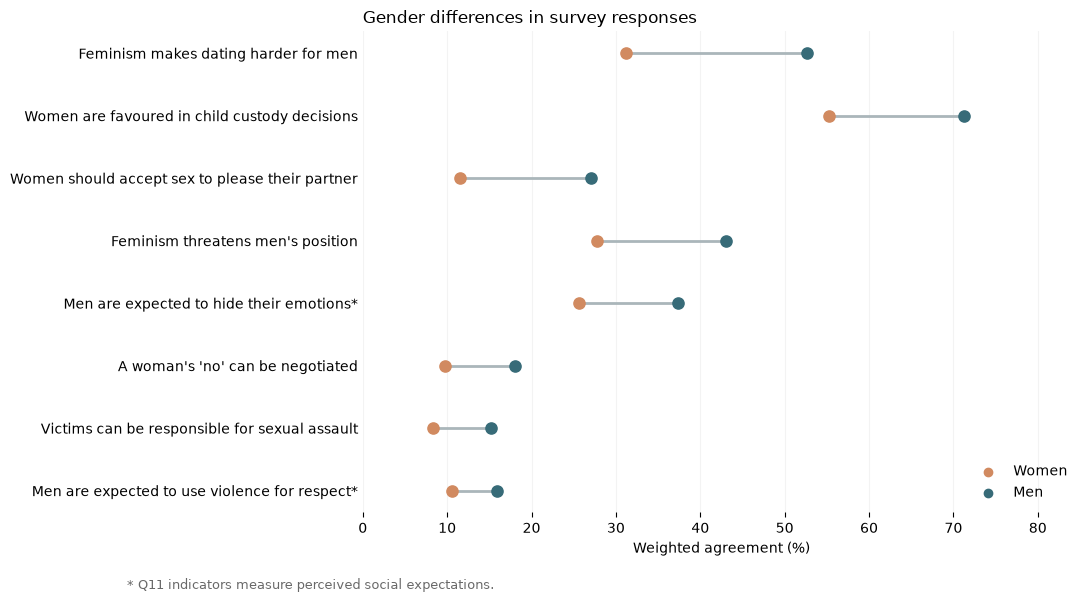

In [12]:
# Compare weighted agreement between women and men

plot_data = gender_comparison.copy()
plot_data["Statement"] = plot_data.index.map(question_labels)
plot_data = plot_data.sort_values("Gap (men - women)")

fig, ax = plt.subplots(figsize=(11, 6))

for i, (_, row) in enumerate(plot_data.iterrows()):
    women = row["Une femme"]
    men = row["Un homme"]

    ax.plot([women, men], [i, i],
            color="#AAB6BA", linewidth=2)

    ax.scatter(women, i, color="#D18A60", s=65, zorder=3)
    ax.scatter(men, i, color="#376B78", s=65, zorder=3)

ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels(plot_data["Statement"])
ax.set_xlim(0, 85)
ax.set_xlabel("Weighted agreement (%)")
ax.set_title("Gender differences in survey responses", loc="left")

# Legend
ax.scatter([], [], color="#D18A60", label="Women")
ax.scatter([], [], color="#376B78", label="Men")
ax.legend(frameon=False, loc="lower right")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.15)

plt.figtext(
    0.12, 0.01,
    "* Q11 indicators measure perceived social expectations.",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### Observation

Men show higher weighted agreement than women across all
eight selected indicators.

The largest gender gap concerns the statement that feminism
makes dating harder for men (21.4 percentage points).

A notable difference also appears for the statement that women
should accept sex to please their partner: 27.1% of men agree,
compared with 11.5% of women.

These are descriptive differences and do not establish causality.
The Q11 indicators measure perceived social expectations rather
than personal agreement.

### 4.3 Age differences

Do sexist and antifeminist attitudes vary across age groups?

We compare weighted agreement across age groups to identify
possible generational differences.

In [13]:
# Check the age groups available in the dataset

age_col = [
    col for col in df_clean.columns
    if col.startswith("REC_AGE3")
][0]

print("Column:", age_col)
print("\nAge groups:")
print(df_clean[age_col].value_counts(dropna=False))

Column: REC_AGE3 : REC_AGE3

Age groups:
REC_AGE3 : REC_AGE3
65 ans et plus    743
50-64 ans         742
35-49 ans         718
25-34 ans         432
15-24 ans         426
Name: count, dtype: int64


In [14]:
# Compare weighted agreement across age groups

age_results = []

for col in binary_cols:
    for age in df_clean[age_col].unique():

        valid = df_clean[
            (df_clean[age_col] == age)
            & (df_clean[col].notna())
        ]

        percentage = (
            (valid[col] * valid["POIDS"]).sum()
            / valid["POIDS"].sum()
            * 100
        )

        age_results.append({
            "Question": col.replace("_binary", ""),
            "Age group": age,
            "Weighted agreement (%)": round(percentage, 1)
        })

df_age = pd.DataFrame(age_results)

age_comparison = df_age.pivot(
    index="Question",
    columns="Age group",
    values="Weighted agreement (%)"
)

# Display age groups in chronological order
age_order = [
    "15-24 ans",
    "25-34 ans",
    "35-49 ans",
    "50-64 ans",
    "65 ans et plus"
]

age_comparison = age_comparison[age_order]

display(age_comparison)

Age group,15-24 ans,25-34 ans,35-49 ans,50-64 ans,65 ans et plus
Question,,,,,
Q11_6,18.2,27.8,16.4,6.3,4.9
Q11_7,38.7,42.2,34.0,23.9,24.2
Q4_10,11.2,19.2,12.5,6.0,11.6
Q4_19,32.3,41.9,33.9,34.5,34.7
Q4_27,58.2,68.5,61.8,65.7,60.8
Q4_29,17.8,27.0,20.9,13.4,17.3
Q4_30,36.2,49.0,40.0,43.4,39.8
Q4_33,11.8,19.1,16.1,8.8,13.7


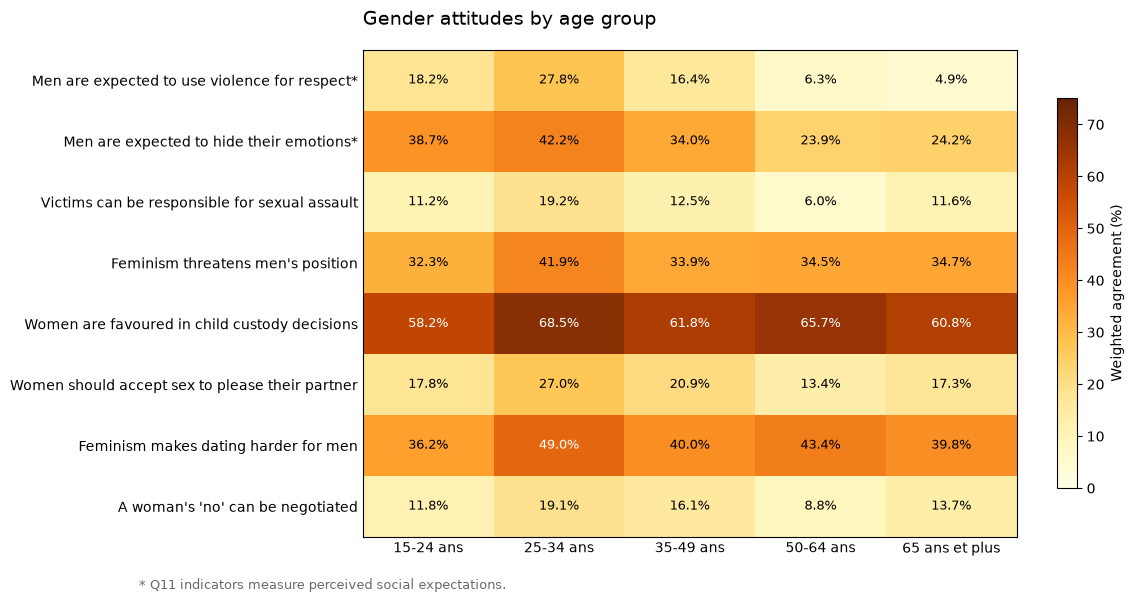

In [15]:
# Visualize weighted agreement across age groups

import matplotlib.pyplot as plt
import numpy as np

plot_data = age_comparison.copy()
plot_data.index = plot_data.index.map(question_labels)

fig, ax = plt.subplots(figsize=(12, 6))

heatmap = ax.imshow(
    plot_data.values,
    cmap="YlOrBr",
    aspect="auto",
    vmin=0,
    vmax=75
)

ax.set_xticks(range(len(age_order)))
ax.set_xticklabels(age_order)

ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels(plot_data.index)

# Display percentages inside the cells
for i in range(len(plot_data)):
    for j in range(len(age_order)):
        value = plot_data.iloc[i, j]

        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 45 else "black",
            fontsize=9
        )

ax.set_title(
    "Gender attitudes by age group",
    loc="left",
    fontsize=14,
    pad=18
)

ax.tick_params(axis="both", length=0)

plt.colorbar(
    heatmap,
    ax=ax,
    label="Weighted agreement (%)",
    shrink=0.8
)

fig.text(
    0.12, 0.01,
    "* Q11 indicators measure perceived social expectations.",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### Observation

The 25-34 age group shows the highest weighted percentage
across all eight selected indicators.

For example, 41.9% agree that feminism threatens men's position,
compared with 32.3% among respondents aged 15-24.

The results do not show a simple increase in agreement with age.
However, they suggest that age differences deserve further attention.

These findings are descriptive and cannot establish generational
effects or predict individual behaviour.

In [16]:
# Search for questions related to incest and protective mothers

keywords = [
    "inceste",
    "incest",
    "mère protectrice",
    "mères protectrices",
    "protection de l'enfant",
    "violences sexuelles sur mineur"
]

matching_cols = [
    col for col in df_hce.columns
    if any(word in col.lower() for word in keywords)
]

print("Matching columns:", len(matching_cols))

for col in matching_cols:
    print(col)

Matching columns: 0


## 5. Territorial Analysis: Recorded Violence

### 5.1 Data Loading & Understanding

How do recorded violence levels differ across the four CIDFF departments?

We use SSMSI data to explore recorded violence in Isère (38),
Rhône (69), Savoie (73) and Haute-Savoie (74).

These figures represent incidents recorded by police and
gendarmerie, not all violence experienced by victims.

In [17]:
# Load the SSMSI departmental dataset

df_ssmsi = pd.read_csv(
    "data/raw/donnee-dep-data.gouv-2025-geographie2026-produit-le2026-06-25.csv",
    sep=";",
    low_memory=False
)

print("Rows and columns:", df_ssmsi.shape)
display(df_ssmsi.head())
print("\nColumns:")
print(df_ssmsi.columns.tolist())

Rows and columns: (18180, 11)


,Code_departement,Code_region,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime
0,01,84,2016,Homicides,Victime,5,"0,0078318",638425,2016,308491,2016
1,02,32,2016,Homicides,Victime,10,"0,0186520",536136,2016,264180,2016
2,03,84,2016,Homicides,Victime,4,"0,0117861",339384,2016,206980,2016
3,04,93,2016,Homicides,Victime,2,"0,0123028",162565,2016,126760,2016
4,05,93,2016,Homicides,Victime,0,"0,0000000",141107,2016,134647,2016



Columns:
['Code_departement', 'Code_region', 'annee', 'indicateur', 'unite_de_compte', 'nombre', 'taux_pour_mille', 'insee_pop', 'insee_pop_millesime', 'insee_log', 'insee_log_millesime']


In [18]:
# Explore the available years and indicators

print("Years:")
print(sorted(df_ssmsi["annee"].unique()))

print("\nIndicators:")
for indicator in sorted(df_ssmsi["indicateur"].unique()):
    print(indicator)

print("\nData types:")
print(df_ssmsi.dtypes)

Years:
[np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Indicators:
Cambriolages de logement
Destructions et dégradations volontaires
Escroqueries et fraudes aux moyens de paiement
Homicides
Tentatives d'homicide
Trafic de stupéfiants
Usage de stupéfiants
Usage de stupéfiants (AFD)
Usage de stupéfiants (hors AFD)
Violences physiques hors cadre familial
Violences physiques intrafamiliales
Violences sexuelles
Vols avec armes
Vols d'accessoires sur véhicules
Vols dans les véhicules
Vols de véhicule
Vols sans violence contre des personnes
Vols violents sans arme

Data types:
Code_departement         str
Code_region            int64
annee                  int64
indicateur               str
unite_de_compte          str
nombre                 int64
taux_pour_mille          str
insee_pop              int64
insee_pop_millesime    int64
insee_log              int64
insee_log_millesime

### 5.2 Data Cleaning

We focus on two indicators: intrafamily physical violence
and sexual violence.

We select the four CIDFF departments and convert the
recorded rates into numeric values.

In [19]:
# Select the four CIDFF departments and relevant indicators

departments = ["38", "69", "73", "74"]

indicators = [
    "Violences physiques intrafamiliales",
    "Violences sexuelles"
]

df_violence = df_ssmsi[
    df_ssmsi["Code_departement"].isin(departments)
    & df_ssmsi["indicateur"].isin(indicators)
].copy()

# Convert French decimal values to numeric
df_violence["taux_pour_mille"] = pd.to_numeric(
    df_violence["taux_pour_mille"].str.replace(",", ".", regex=False),
    errors="coerce"
)

print("Rows and columns:", df_violence.shape)
print("Missing rates:", df_violence["taux_pour_mille"].isna().sum())

display(df_violence.head())

Rows and columns: (80, 11)
Missing rates: 0


,Code_departement,Code_region,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime
2058,38,84,2016,Violences physiques intrafamiliales,Victime,1826,1.457405,1252912,2016,639743,2016
2089,69,84,2016,Violences physiques intrafamiliales,Victime,3170,1.726671,1835903,2016,904462,2016
2093,73,84,2016,Violences physiques intrafamiliales,Victime,532,1.238128,429681,2016,341648,2016
2094,74,84,2016,Violences physiques intrafamiliales,Victime,1049,1.308933,801416,2016,500698,2016
2159,38,84,2017,Violences physiques intrafamiliales,Victime,1956,1.553957,1258722,2017,646707,2017


### 5.3 Evolution of Recorded Violence

How have recorded violence rates changed between 2016 and 2025
across the four CIDFF departments?

We compare rates per 1,000 inhabitants rather than raw counts,
because department populations are different.

In [20]:
# Compare yearly recorded violence rates by department

department_names = {
    "38": "Isère",
    "69": "Rhône",
    "73": "Savoie",
    "74": "Haute-Savoie"
}

df_violence["department"] = (
    df_violence["Code_departement"].map(department_names)
)

display(
    df_violence.groupby(
        ["indicateur", "department"]
    )["taux_pour_mille"].agg(["min", "max", "mean"]).round(2)
)

min   max  mean
indicateur                          department                    
Violences physiques intrafamiliales Haute-Savoie  1.24  3.29  2.23
                                    Isère         1.46  3.44  2.48
                                    Rhône         1.70  3.08  2.49
                                    Savoie        1.16  2.97  2.17
Violences sexuelles                 Haute-Savoie  0.65  1.65  1.09
                                    Isère         0.70  1.81  1.22
                                    Rhône         0.75  1.79  1.24
                                    Savoie        0.73  1.74  1.22

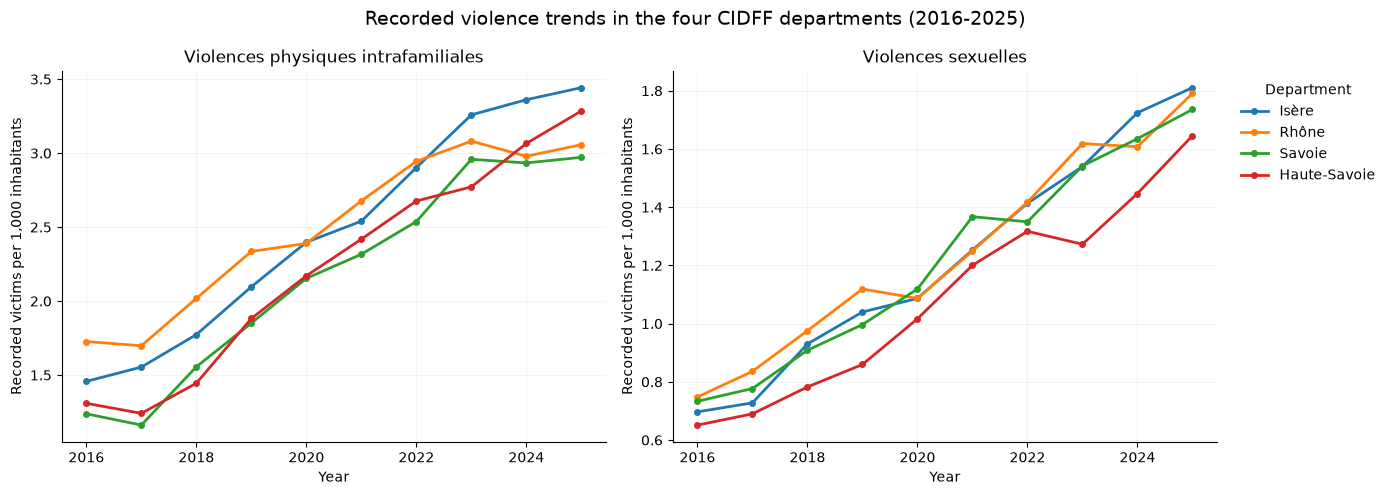

In [21]:
# Visualize yearly trends in recorded violence rates

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, indicator in zip(axes, indicators):
    subset = df_violence[
        df_violence["indicateur"] == indicator
    ]

    for department in department_names.values():
        data = subset[
            subset["department"] == department
        ].sort_values("annee")

        ax.plot(
            data["annee"],
            data["taux_pour_mille"],
            marker="o",
            linewidth=2,
            markersize=4,
            label=department
        )

    ax.set_title(indicator, fontsize=12)
    ax.set_xlabel("Year")
    ax.set_ylabel("Recorded victims per 1,000 inhabitants")
    ax.set_xticks(range(2016, 2026, 2))
    ax.grid(alpha=0.15)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

axes[1].legend(
    title="Department",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.suptitle(
    "Recorded violence trends in the four CIDFF departments (2016-2025)",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Observation

Recorded rates of intrafamily physical violence and sexual violence increased between 2016 and 2025 in all four departments.

However, this increase does not necessarily mean that violence itself increased at the same rate.

Several factors may have contributed to these trends, including greater public awareness after #MeToo, support from associations, better identification of victims, and changes in police reporting and recording practices.

The 2019 Grenelle on domestic violence and efforts to improve police training may also have played a role.

These are possible explanations, not conclusions from this dataset.

A comparison with the evolution of local associations could help explore these hypotheses, but would not establish causality.

In [22]:
# Compare recorded rates between 2016 and 2025

comparison = df_violence[
    df_violence["annee"].isin([2016, 2025])
].pivot_table(
    index=["indicateur", "department"],
    columns="annee",
    values="taux_pour_mille"
)

comparison["Change (%)"] = (
    (comparison[2025] - comparison[2016])
    / comparison[2016] * 100
).round(1)

display(comparison.round(2))

annee                                             2016  2025  Change (%)
indicateur                          department                          
Violences physiques intrafamiliales Haute-Savoie  1.31  3.29       151.0
                                    Isère         1.46  3.44       136.2
                                    Rhône         1.73  3.06        77.0
                                    Savoie        1.24  2.97       140.0
Violences sexuelles                 Haute-Savoie  0.65  1.65       152.6
                                    Isère         0.70  1.81       159.9
                                    Rhône         0.75  1.79       139.5
                                    Savoie        0.73  1.74       136.8

### Observation

Between 2016 and 2025, recorded intrafamily physical violence
rates increased by 77% to 151% across the four departments.

Recorded sexual violence rates increased by 136.8% to 159.9%.

The largest increase in intrafamily physical violence was
observed in Haute-Savoie (+151%), while Isère had the largest
increase in recorded sexual violence (+159.9%).

These changes may reflect several factors, including changes
in reporting, identification and recording practices.

They cannot be interpreted as equivalent increases in the
actual prevalence of violence.

In [23]:
# Compare recorded violence rates across departments in 2025

df_2025 = df_violence[
    df_violence["annee"] == 2025
]

comparison_2025 = df_2025.pivot(
    index="department",
    columns="indicateur",
    values="taux_pour_mille"
)

display(comparison_2025.round(2))

indicateur,Violences physiques intrafamiliales,Violences sexuelles
department,,
Haute-Savoie,3.29,1.65
Isère,3.44,1.81
Rhône,3.06,1.79
Savoie,2.97,1.74


### 5.4 Yearly Changes in Recorded Violence

Did recorded violence rates increase steadily, or were
there periods of faster growth?

We calculate yearly percentage changes to identify
possible changes in trends.

In [24]:
# Calculate yearly percentage changes

df_trends = df_violence.sort_values(
    ["indicateur", "department", "annee"]
).copy()

df_trends["yearly_change_pct"] = (
    df_trends.groupby(
        ["indicateur", "department"]
    )["taux_pour_mille"]
    .pct_change() * 100
)

# Average yearly change across the four departments
yearly_summary = (
    df_trends.groupby(
        ["indicateur", "annee"]
    )["yearly_change_pct"]
    .mean()
    .unstack(0)
)

display(yearly_summary.round(1))

indicateur,Violences physiques intrafamiliales,Violences sexuelles
annee,,
2016,NaN,NaN
2017,-1.6,7.0
2018,20.8,18.7
2019,20.8,11.5
2020,12.1,8.0
2021,9.2,17.7
2022,11.1,8.7
2023,9.3,8.5
2024,2.4,7.8


### Observation

The yearly changes show that recorded violence rates did not increase at a constant pace.

In 2018 and 2019, intrafamily physical violence rates increased by an average of 20.8% per year across the four departments.

Recorded sexual violence rates also showed strong increases in 2018 (+18.7%) and 2021 (+17.7%).

These changes occurred during a period of growing public awareness and policy attention to violence against women, including #MeToo and the 2019 Grenelle.

However, this dataset cannot establish a causal relationship between these events and recorded violence trends.

Changes in reporting, identification and recording practices may contribute to these patterns.

### Final Data Limitation

The full SSMSI dataset contains 18 indicators.

None of them directly identifies psychological, economic
or administrative abuse, coercive control, or incest.

Our analysis therefore focuses on two measurable categories:
recorded intrafamily physical violence and sexual violence.

These indicators provide useful information about recorded
violence trends, but they do not represent all forms of
violence or all victims' support needs.

## 6. Intrafamily Violence Against Minors

### 6.1 Departmental Comparison (2022–2024)

How do recorded rates of intrafamily violence against minors
compare across our four departments?

In [25]:
# Load departmental rates for minors from the SSMSI Excel file

file_path = "data/raw/Données_IR59_violences_intrafamiliales_2024.xlsx"

df_physical_minors = pd.read_excel(
    file_path, sheet_name="Figure 8a", header=2,
    usecols="A:C"
)

df_sexual_minors = pd.read_excel(
    file_path, sheet_name="Figure 8b", header=2,
    usecols="A:C"
)

display(df_physical_minors.head())
display(df_sexual_minors.head())

,Départements,Unnamed: 1,Taux\n(‰)
0,1,Ain,2.873838
1,2,Aisne,3.928897
2,3,Allier,3.203438
3,4,Alpes-de-Haute-Provence,3.436975
4,5,Hautes-Alpes,3.162651


,Départements,Unnamed: 1,Taux\n(‰)
0,1,Ain,0.959361
1,2,Aisne,2.163036
2,3,Allier,1.681393
3,4,Alpes-de-Haute-Provence,1.574837
4,5,Hautes-Alpes,1.405622


In [26]:
# Rename columns and select our four departments

target_departments = [
    "Isère", "Rhône", "Savoie", "Haute-Savoie"
]

df_physical_minors.columns = ["code", "department", "rate"]
df_sexual_minors.columns = ["code", "department", "rate"]

physical_4 = df_physical_minors[
    df_physical_minors["department"].isin(target_departments)
].copy()

sexual_4 = df_sexual_minors[
    df_sexual_minors["department"].isin(target_departments)
].copy()

physical_4["violence_type"] = "Physical violence"
sexual_4["violence_type"] = "Sexual violence"

df_minors = pd.concat(
    [physical_4, sexual_4],
    ignore_index=True
)

display(df_minors)

,code,department,rate,violence_type
0,38,Isère,3.463689,Physical violence
1,69,Rhône,2.147580,Physical violence
2,73,Savoie,2.882646,Physical violence
3,74,Haute-Savoie,2.289169,Physical violence
4,38,Isère,1.172379,Sexual violence
5,69,Rhône,0.843378,Sexual violence
6,73,Savoie,1.016974,Sexual violence
7,74,Haute-Savoie,0.975278,Sexual violence


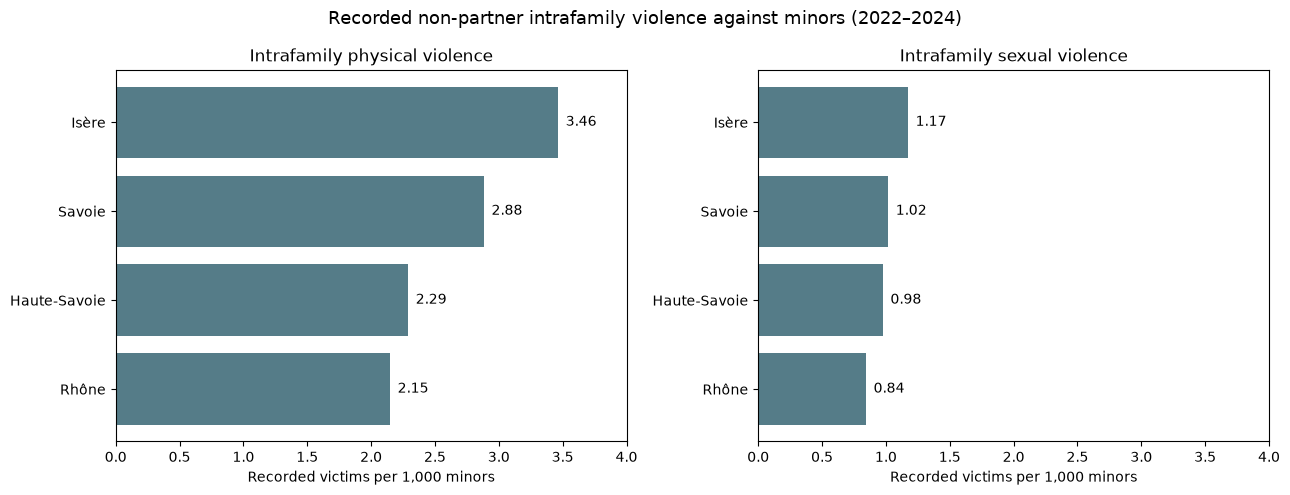

In [27]:
# Compare recorded intrafamily violence rates against minors

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

violence_labels = {
    "Physical violence": "Intrafamily physical violence",
    "Sexual violence": "Intrafamily sexual violence"
}

for ax, (violence_type, title) in zip(
    axes, violence_labels.items()
):
    data = df_minors[
        df_minors["violence_type"] == violence_type
    ].sort_values("rate")

    ax.barh(data["department"], data["rate"], color="#557C88")

    ax.set_title(title)
    ax.set_xlabel("Recorded victims per 1,000 minors")
    ax.set_xlim(0, 4)

    for i, rate in enumerate(data["rate"]):
        ax.text(rate + 0.06, i, f"{rate:.2f}", va="center")

fig.suptitle(
    "Recorded non-partner intrafamily violence against minors (2022–2024)",
    fontsize=13
)

plt.tight_layout()
plt.show()

### Observation

Between 2022 and 2024, Isère had the highest average annual
recorded rates of non-partner intrafamily physical and sexual
violence against minors among the four departments.

Savoie ranked second for both indicators, while Rhône had
the lowest recorded rates.

These differences may reflect variations in reporting,
identification, recording practices or actual violence.

Sexual violence within the family may include incest, but
this dataset does not measure incest separately.

These indicators should therefore be interpreted as partial
measures of children's protection and support needs.

### 6.2 Reporting Delays Over Time (2016–2024)

How has the time between the beginning of intrafamily
violence and its recording by the police changed over time?

In [28]:
# Explore average recording delays (in months)

df_delays_raw = pd.read_excel(
    file_path,
    sheet_name="Figure complémentaire 5",
    header=None
)

display(df_delays_raw.iloc[:10, :12])

,0,1,2,3,4,5,6,7,8,9,10
0,Figure complémentaire 5 : Délai moyen entre le...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,violences intrafamiliales non conjugales,NaN,2016.0,2017.0,2018.0,2019.000,2020.000000,2021.000000,2022.000000,2023.000000,2024.000000
3,Violences physiques,Majeurs,2.0,2.0,2.0,2.722,3.159162,3.898795,3.954117,4.041158,4.041158
4,NaN,Mineurs,10.0,11.0,12.0,14.000,16.000000,19.000000,20.000000,21.000000,22.000000
5,Violences sexuelles,Majeurs,26.0,31.0,31.0,30.000,34.000000,41.000000,39.000000,42.000000,49.000000
6,NaN,Mineurs,49.0,52.0,56.0,61.000,64.000000,81.000000,88.000000,84.000000,86.000000
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Note : L’âge des victimes est calculé au momen...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,"Lecture : En 2016, le délai moyen entre le déb...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


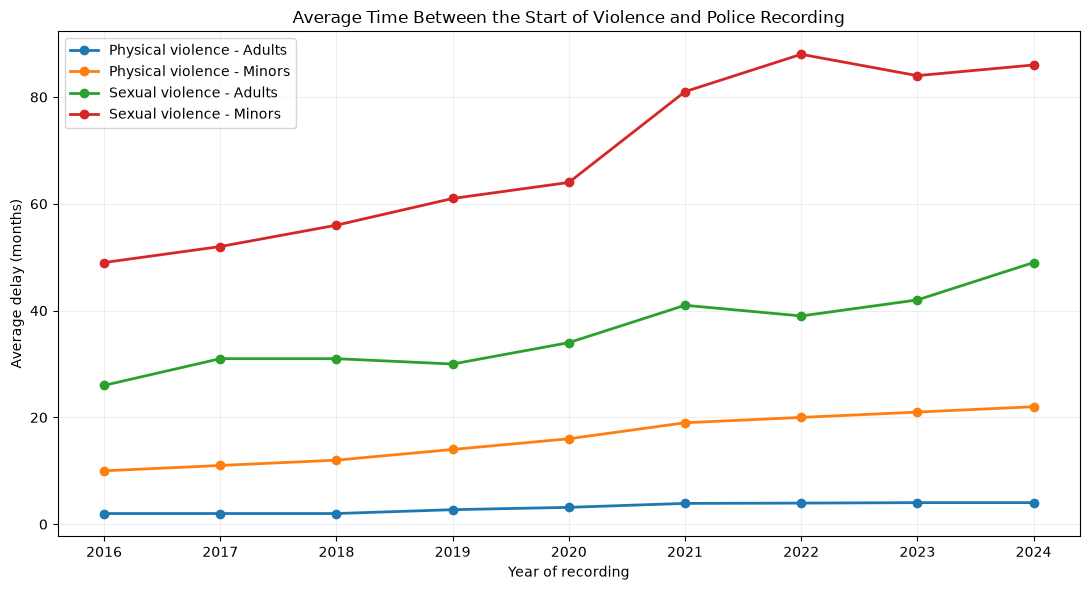

In [29]:
# Prepare the yearly recording delays

years = df_delays_raw.iloc[2, 2:11].astype(int).tolist()

delay_data = {
    "Physical violence - Adults": 3,
    "Physical violence - Minors": 4,
    "Sexual violence - Adults": 5,
    "Sexual violence - Minors": 6
}

plt.figure(figsize=(11, 6))

for label, row in delay_data.items():
    delays = pd.to_numeric(
        df_delays_raw.iloc[row, 2:11],
        errors="coerce"
    )

    plt.plot(
        years,
        delays,
        marker="o",
        linewidth=2,
        label=label
    )

plt.title(
    "Average Time Between the Start of Violence and Police Recording"
)
plt.xlabel("Year of recording")
plt.ylabel("Average delay (months)")
plt.xticks(years)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Observation

Between 2016 and 2024, the average time between the start
of intrafamily violence and police recording increased
across all four categories.

The longest delays concern sexual violence experienced
during childhood, increasing from 49 months in 2016
to 86 months in 2024.

A particularly strong increase occurred between 2020
and 2021, from 64 to 81 months.

This may suggest that more historical cases are being
recorded, but the data cannot explain why.

These national trends highlight the importance of
supporting victims who disclose violence many years
after the events began.

In [30]:
# Explore how recording delays changed over time

df_delay_distribution = pd.read_excel(
    file_path,
    sheet_name="Figure complémentaire 6",
    header=None
)

sexual_delay = df_delay_distribution.iloc[18:23, 0:10].copy()

sexual_delay.columns = ["delay"] + list(range(2016, 2025))

display(sexual_delay)

,delay,2016,2017,2018,2019,2020,2021,2022,2023,2024
18,Moins d'un an,41.0,39.0,38.0,38.0,36.0,31.0,30.0,31.0,30.0
19,1 à 5 ans,31.0,32.0,32.0,31.0,31.0,29.0,28.0,28.0,29.0
20,5 à 20 ans,24.0,24.0,25.0,25.0,27.0,31.0,30.0,31.0,31.0
21,20 à 30 ans,3.0,3.0,4.0,4.0,4.0,5.0,5.0,5.0,5.0
22,30 ans et plus,1.0,1.0,2.0,2.0,3.0,5.0,6.0,5.0,6.0


In [31]:
# Use delay categories as row labels
delay_plot = sexual_delay.set_index("delay").copy()

# Translate the labels into English
delay_plot.index = [
    "Less than 1 year",
    "1–5 years",
    "5–20 years",
    "20–30 years",
    "30+ years"
]

# Convert percentages to numbers
delay_plot = delay_plot.apply(pd.to_numeric, errors="raise")

# Use the years available in this table
years = delay_plot.columns.tolist()

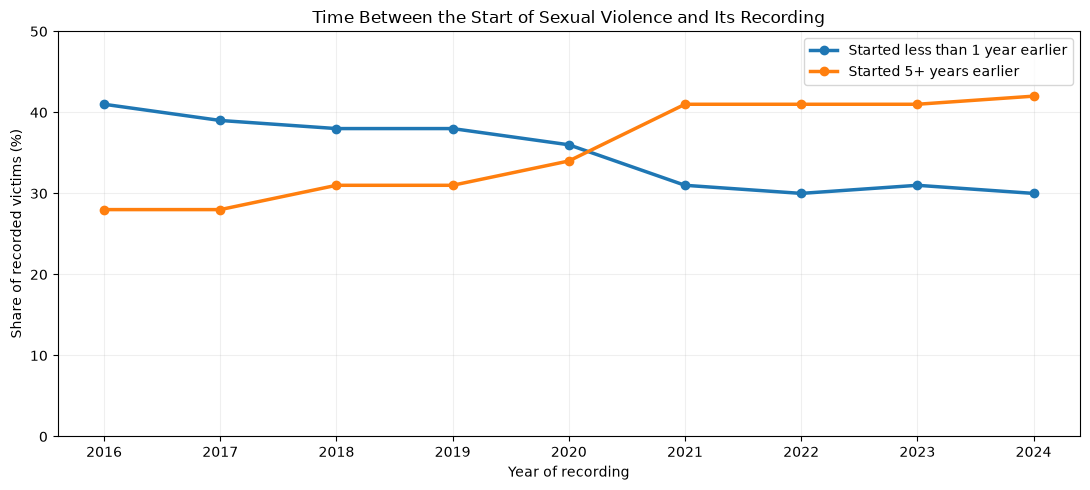

In [43]:
# Compare recent and older recorded violence over time

recent_cases = delay_plot.loc["Less than 1 year"]

older_cases = delay_plot.loc[
    ["5–20 years", "20–30 years", "30+ years"]
].sum()

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    years, recent_cases,
    marker="o", linewidth=2.5,
    label="Started less than 1 year earlier"
)

ax.plot(
    years, older_cases,
    marker="o", linewidth=2.5,
    label="Started 5+ years earlier"
)

ax.set_title(
    "Time Between the Start of Sexual Violence and Its Recording"
)
ax.set_xlabel("Year of recording")
ax.set_ylabel("Share of recorded victims (%)")
ax.set_xticks(years)
ax.set_ylim(0, 50)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Observation

Between 2016 and 2024, the share of recorded intrafamily
sexual violence cases that started at least five years
earlier increased from 28% to approximately 42%.

At the same time, the share of cases recorded less than
one year after the first incident decreased from 41% to 30%.

This suggests that older cases represent a growing share
of recorded sexual violence.

However, these data do not explain why these changes occurred.

In [33]:
# Explore sexual violence recorded against minors

df_child_sexual = pd.read_excel(
    file_path,
    sheet_name="Figure complémentaire 9",
    header=None
)

display(df_child_sexual.iloc[:18, :12])

,0,1,2,3,4,5,6,7
0,Figure complémentaire 9 - Types de violences i...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Nombre de victimes mineures enregistrées,Ensemble,Sexe de la victime,NaN,Âge de la victime au moment des faits,NaN,NaN,NaN
3,NaN,NaN,F,H,0-4 ans,5-9 ans,10-14 ans,15-17 ans
4,Ensemble violences sexuelles,19254,15322,3932,4719,7518,5367,1650
5,Violences sexuelles physiques,17083,13758,3325,4363,6819,4535,1366
6,Viol ou tentative de viol,6371,5056,1315,1630,2633,1563,545
7,Agression sexuelle,10331,8415,1916,2634,4050,2853,794
8,Atteinte sexuelle,381,287,94,99,136,119,27
9,Violences sexuelles non physiques,162,149,13,8,34,69,51


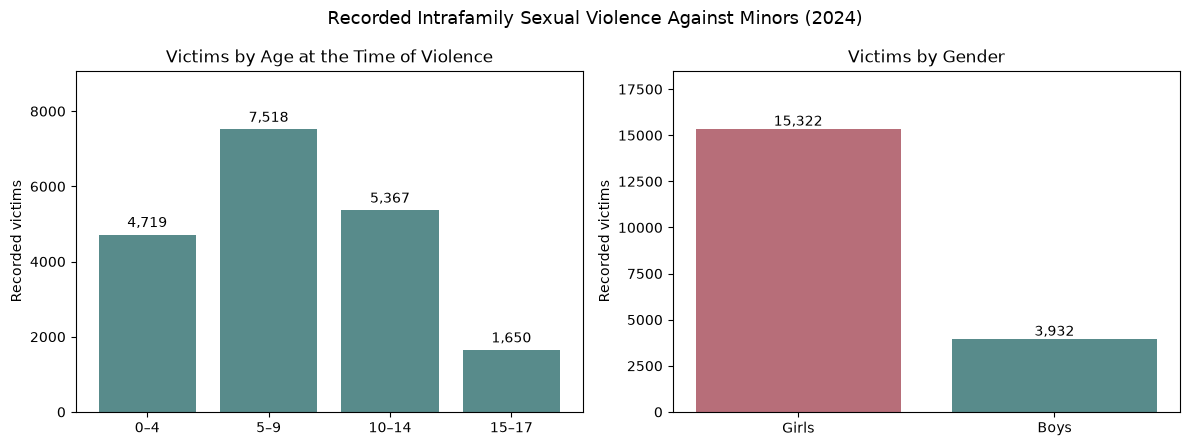

In [34]:
# Distribution of recorded victims by age and gender

age_labels = ["0–4", "5–9", "10–14", "15–17"]
age_counts = [4719, 7518, 5367, 1650]

gender_labels = ["Girls", "Boys"]
gender_counts = [15322, 3932]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Age distribution
axes[0].bar(age_labels, age_counts, color="#588B8B")
axes[0].set_title("Victims by Age at the Time of Violence")
axes[0].set_ylabel("Recorded victims")

# Gender distribution
axes[1].bar(gender_labels, gender_counts, color=["#B76E79", "#588B8B"])
axes[1].set_title("Victims by Gender")
axes[1].set_ylabel("Recorded victims")

for ax in axes:
    for bar in ax.patches:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 200,
            f"{int(bar.get_height()):,}",
            ha="center"
        )
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)

fig.suptitle(
    "Recorded Intrafamily Sexual Violence Against Minors (2024)",
    fontsize=13
)

plt.tight_layout()
plt.show()

### Observation — Age and Gender of Victims

In 2024, 19,254 victims of non-partner intrafamily sexual
violence were recorded as minors at the time of the events.

Girls represented 79.6% of recorded victims, compared
with 20.4% for boys.

Almost two-thirds of victims were under 10 years old
when the violence occurred (63.5%).

The largest age group was 5–9 years old (39%).

These results highlight the importance of early identification
and child protection, especially for young children.

However, the age refers to the time of the events, not
necessarily the time of police recording.

In [35]:
# Explore the relationship between victims and perpetrators

df_family_links = pd.read_excel(
    file_path,
    sheet_name="Figure complémentaire 11",
    header=None
)

display(df_family_links.iloc[:18, :12])

,0,1,2,3,4
0,Figure complémentaire 11 - Lien familial entr...,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,NaN,Moins de 10 ans,10 - 14 ans,15 ans et plus,Ensemble
5,Parents,43,31,30,38
6,Beaux-parents,18,39,36,25
7,Grands-parents,10,6,5,9
8,Frères et sœurs,18,13,10,16
9,Descendants,0,0,4,1


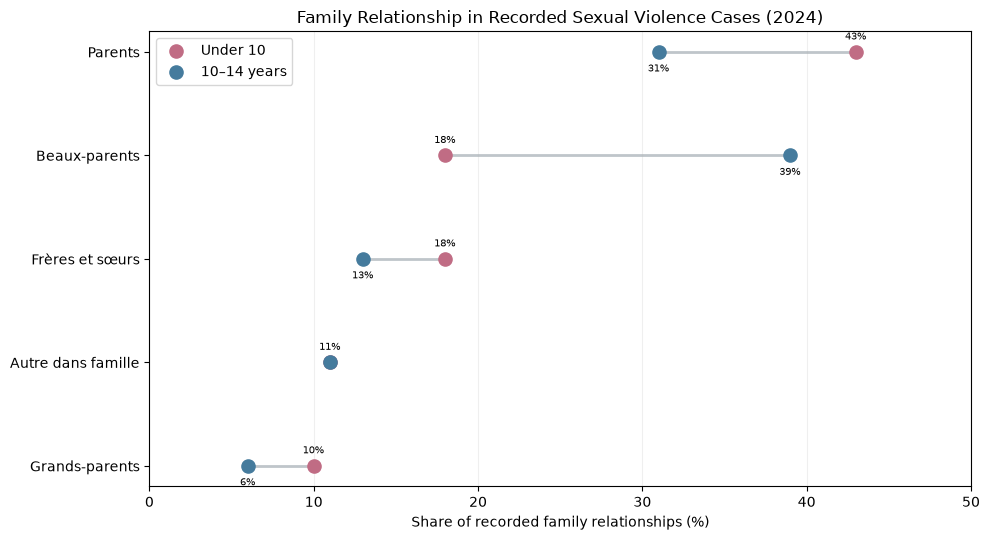

In [36]:
# Compare family relationships across two age groups

family_data = df_family_links.iloc[5:11, 0:4].copy()

family_data.columns = [
    "relationship", "Under 10", "10–14", "15+"
]

family_data = family_data.set_index("relationship")
family_data = family_data.apply(pd.to_numeric)

# Keep only relevant categories
family_compare = family_data[
    ["Under 10", "10–14"]
].drop(index="Descendants").sort_values(
    "Under 10"
)

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, (relationship, row) in enumerate(family_compare.iterrows()):

    under_10 = row["Under 10"]
    age_10_14 = row["10–14"]

    # Connect the two age groups
    ax.plot(
        [under_10, age_10_14],
        [i, i],
        color="#BFC5CA",
        linewidth=2,
        zorder=1
    )

    # Add labels with the same font size
    ax.annotate(
        f"{under_10:.0f}%",
        (under_10, i),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=7
    )

    if under_10 != age_10_14:
        ax.annotate(
            f"{age_10_14:.0f}%",
            (age_10_14, i),
            xytext=(0, -14),
            textcoords="offset points",
            ha="center",
            fontsize=7
        )

ax.scatter(
    family_compare["Under 10"],
    range(len(family_compare)),
    color="#C06C84",
    s=90,
    label="Under 10",
    zorder=2
)

ax.scatter(
    family_compare["10–14"],
    range(len(family_compare)),
    color="#457B9D",
    s=90,
    label="10–14 years",
    zorder=2
)

ax.set_yticks(range(len(family_compare)))
ax.set_yticklabels(family_compare.index)

ax.set_xlabel("Share of recorded family relationships (%)")
ax.set_title(
    "Family Relationship in Recorded Sexual Violence Cases (2024)"
)

ax.set_xlim(0, 50)
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### Observation — Family Relationship with the Perpetrator

In 2024, parents represented 43% of recorded family
relationships in sexual violence cases involving victims
under 10 years old.

When including step-parents, this share reached 61%.

Among victims aged 10–14, step-parents represented
39% of recorded family relationships, compared with
31% for parents.

These results highlight the importance of considering
the child's family environment when identifying
protection and support needs.

The figures describe recorded cases and do not measure
the prevalence of incest in the general population.

In [37]:
# Check the available information about victims' age

for sheet in ["Figure 6", "Figure complémentaire 9"]:
    print(f"\n--- {sheet} ---")

    data = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None
    )

    display(data.tail(8))


--- Figure 6 ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
3,NaN,0-4 ans,5-9 ans,10-14 ans,15-19 ans,20-24 ans,25-29 ans,30-34 ans,35-39 ans,40-44 ans,45-49 ans,50-54 ans,55-59 ans,60-64 ans,65-69 ans,70-74 ans,75ans et plus
4,Femme,17.11,29.23,22.53,8.51,0.83,0.39,0.28,0.31,0.17,0.13,0.1,0.09,0.09,0.05,0.05,0.05
5,Homme,6.34,8.14,4.15,1.02,0.09,0.08,0.05,0.04,0.05,0.05,0.01,0,0,0,0,0.01
6,% de femmes,72.96,78.23,84.44,89.25,89.73,83.16,83.58,88.73,76.09,72.97,87.5,100,100,100,100,84.62
7,Note : L’âge des victimes est calculé au momen...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,"Lecture : En 2024, 23 % des victimes de violen...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Champ : France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,"Source : SSMSI, base statistique des victimes ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Figure complémentaire 9 ---


,0,1,2,3,4,5,6,7
13,Pédopornographie,242,204,38,40,59,107,36
14,Corruption de mineur,1417,968,449,250,485,519,163
15,Exhibition sexuelle,320,216,104,51,116,127,26
16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,Note : L’âge des victimes est calculé au momen...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,"Lecture : En 2024, les forces de sécurité ont ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
19,Champ : France,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,"Source : SSMSI, base statistique des victimes ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
# Read the full methodological notes

for sheet, row in [
    ("Figure 6", 7),
    ("Figure complémentaire 9", 17)
]:
    data = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None
    )

    print(f"\n{sheet}")
    print(data.iloc[row, 0])


Figure 6
Note : L’âge des victimes est calculé au moment des faits

Figure complémentaire 9
Note : L’âge des victimes est calculé au moment des faits


In [39]:
# Prepare clean datasets for SQL and Tableau

# Keep original dataframes unchanged
violence_export = df_violence.copy()
minors_export = df_minors.copy()

# Rename columns
violence_export = violence_export.rename(columns={
    "Code_departement": "department_code",
    "Code_region": "region_code",
    "annee": "year",
    "indicateur": "violence_type",
    "unite_de_compte": "count_unit",
    "nombre": "recorded_victims",
    "taux_pour_mille": "rate_per_1000",
    "insee_pop": "population",
    "insee_pop_millesime": "population_reference_year",
    "insee_log": "housing_units",
    "insee_log_millesime": "housing_reference_year"
})

minors_export = minors_export.rename(columns={
    "code": "department_code",
    "rate": "rate_per_1000_minors"
})

# Add the reference period for minors' data
minors_export["period"] = "2022-2024"

# Check the final columns
print("Violence dataset:")
print(violence_export.columns.tolist())

print("\nMinors dataset:")
print(minors_export.columns.tolist())

Violence dataset:
['department_code', 'region_code', 'year', 'violence_type', 'count_unit', 'recorded_victims', 'rate_per_1000', 'population', 'population_reference_year', 'housing_units', 'housing_reference_year', 'department']

Minors dataset:
['department_code', 'department', 'rate_per_1000_minors', 'violence_type', 'period']


In [40]:
# Save cleaned datasets for SQL and Tableau

from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

violence_export.to_csv(
    output_dir / "department_violence.csv",
    index=False
)

minors_export.to_csv(
    output_dir / "minor_intrafamily_violence.csv",
    index=False
)

print("Datasets saved successfully.")
print(f"Violence: {len(violence_export)} rows")
print(f"Minors: {len(minors_export)} rows")

Datasets saved successfully.
Violence: 80 rows
Minors: 8 rows
